In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
file_path = '/content/drive/My Drive/helmet detection'

In [ ]:
#base augmentation for with helmet
train_datagen_majority = ImageDataGenerator(
    rescale = 1./255,
    horizontal_flip = True,
    zoom_range = 0.5,
    rotation_range = 10,
)
                                            ##zoom_range = 0.2, width_shift_range = 0.2,
                                            ##height_shift_range = 0.2)
#data augumentation for without helmet
train_datagen_minority = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

In [ ]:
#load training set altogether
train = train_datagen_majority.flow_from_directory(
    "/content/drive/My Drive/helmet detection/train",
    target_size=(128, 128 ),
    batch_size=32,
    color_mode='rgb',
    class_mode='binary'

)

# Preprocessing for validation data
valid_datagen = ImageDataGenerator(rescale=1./255)


# Load validation data (without augmentation)
validation = valid_datagen.flow_from_directory(
    "/content/drive/My Drive/helmet detection/valid",
    class_mode='binary',
    target_size=(128, 128),
    batch_size=32,
    color_mode='rgb'
)

Found 3640 images belonging to 2 classes.
Found 2459 images belonging to 2 classes.


In [ ]:
#Data Augmentation for Minority Class (without helmet images):
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import backend as K


# Get class labels from train generator
class_labels = train.classes  # with helmet will be 0, without helmet will be 1 (check using train.class_indices)

# Compute class weights
# for balancing the weights
#class_labels = train.classes
#class_weights = compute_class_weight(class_weight='balanced',
 #classes=np.unique(class_labels), y=class_labels)

# Store in dictionary for Keras
#class_weight_dict = {i: weight for i, weight in enumerate(class_weights)}

# Print for confirmation
#print("Computed Class Weights:", class_weight_dict)

def focal_loss(alpha=0.25, gamma=2.0):
    def focal_loss_fixed(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        bce = K.binary_crossentropy(y_true, y_pred)
        y_pred = K.clip(y_pred, K.epsilon(), 1. - K.epsilon())
        p_t = y_true * y_pred + (1 - y_true) * (1 - y_pred)
        alpha_factor = y_true * alpha + (1 - y_true) * (1 - alpha)
        modulating_factor = tf.pow((1 - p_t), gamma)
        return K.mean(alpha_factor * modulating_factor * bce, axis=-1)
    return focal_loss_fixed

In [ ]:
# Initializing the CNN model using Sequential
cnn = models.Sequential([

    # Input layer for 128x128 RGB images
    # Increased image size would capture more fine-grained details but may slow training
    layers.Input(shape=(128, 128, 3)),

    # First convolution block
    layers.Conv2D(filters=32, kernel_size=3, activation='relu', padding='same'),  # Detects basic patterns
    layers.MaxPooling2D(pool_size=2),  # Downsamples by half

    # Second convolution block
    layers.Conv2D(filters=64, kernel_size=3, activation='relu', padding='same'),  # Captures more detailed features
    layers.MaxPooling2D(pool_size=2),  # Further downsampling

    # Third convolution block
    layers.Conv2D(filters=128, kernel_size=3, activation='relu', padding='same'),  # Learns more complex visual patterns
    layers.MaxPooling2D(pool_size=2),  # Downsampling again

    # Fourth convolution block
    layers.Conv2D(filters=128, kernel_size=3, activation='relu', padding='same'),  # High-level feature extraction
    layers.MaxPooling2D(pool_size=2),  # Final spatial reduction

    # Flattening layer to convert 3D feature maps into 1D vector
    layers.Flatten(),

    # Dropout layer to reduce overfitting by randomly disabling neurons
    layers.Dropout(0.5),

    # Dense layer with 256 neurons to learn patterns from features
    layers.Dense(units=256, activation='relu'),

    # Output layer with 1 neuron for binary classification
    layers.Dense(units=1, activation='sigmoid')
])


In [ ]:
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,338,497 (8.92 MB)

 Trainable params: 2,338,497 (8.92 MB)

 Non-trainable params: 0 (0.00 B)

# Training the cnn model

cnn = tf.keras.models.Sequential([
    tf.keras.Input(shape=(128, 128, 3)),
    tf.keras.layers.Conv2D(32, kernel_size=3, padding='same', activation='relu'),
    tf.keras.layers.MaxPool2D(pool_size=2),
    tf.keras.layers.Conv2D(32, kernel_size=3, padding='same', activation='relu'),
    tf.keras.layers.MaxPool2D(pool_size=2),
    tf.keras.layers.Conv2D(32, kernel_size=3, padding='same', activation='relu'),
    tf.keras.layers.MaxPool2D(pool_size=2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.fit(train, validation_data=validation, epochs=16)

In [ ]:
#adding early stoping
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
from tensorflow.keras.optimizers import Adam

# Create Adam optimizer with smaller learning rate
optimizer = Adam(learning_rate=0.001)

In [ ]:
  # Training the cnn model
cnn.compile(optimizer=optimizer,
            loss=focal_loss(alpha=0.75, gamma=2.0), metrics=['accuracy',  tf.keras.metrics.AUC(name='auc')]
            )

# Train the model and store the history object
history = cnn.fit(train, validation_data=validation,
                  callbacks=[early_stop],
                  #class_weight=class_weight_dict,
                  epochs=20,  verbose=1)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 1771s 16s/step - accuracy: 0.5791 - auc: 0.6219 - loss: 0.0699 - val_accuracy: 0.7397 - val_auc: 0.8242 - val_loss: 0.0548
Epoch 2/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 203s 2s/step - accuracy: 0.6960 - auc: 0.8006 - loss: 0.0550 - val_accuracy: 0.7190 - val_auc: 0.8217 - val_loss: 0.0651
Epoch 3/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 206s 2s/step - accuracy: 0.8201 - auc: 0.8911 - loss: 0.0435 - val_accuracy: 0.8105 - val_auc: 0.8830 - val_loss: 0.0458
Epoch 4/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 259s 2s/step - accuracy: 0.8481 - auc: 0.9123 - loss: 0.0402 - val_accuracy: 0.7804 - val_auc: 0.8799 - val_loss: 0.0474
Epoch 5/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 201s 2s/step - accuracy: 0.8519 - auc: 0.9224 - loss: 0.0368 - val_accuracy: 0.7621 - val_auc: 0.8834 - val_loss: 0.0454
Epoch 6/20
114/114 ━━━━━━━━━━━━━━━━━━━━ 211s 2s/step - accuracy: 0.8733 - auc: 0.9380 - loss: 0.0329 - val_accuracy: 0.8125 - val_auc: 0.8851 - val_loss: 0.0482
Epoch 7/20
114/114 ━━━━━━━━━━━━━

<Axes: >

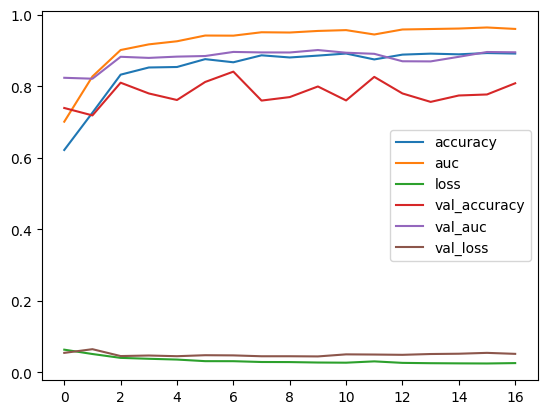

In [ ]:
import pandas as pd
pd.DataFrame(history.history).plot()

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Reset the validation generator to start from the beginning
validation.reset()

# Get predicted probabilities
pred_probs = cnn.predict(validation, verbose=1)

# Convert probabilities to binary class labels (0 or 1)
pred_classes = (pred_probs > 0.5).astype(int).reshape(-1)

77/77 ━━━━━━━━━━━━━━━━━━━━ 36s 470ms/step


In [ ]:
true_classes = validation.classes  # actual labels
class_labels = list(validation.class_indices.keys())  # ['class0', 'class1']

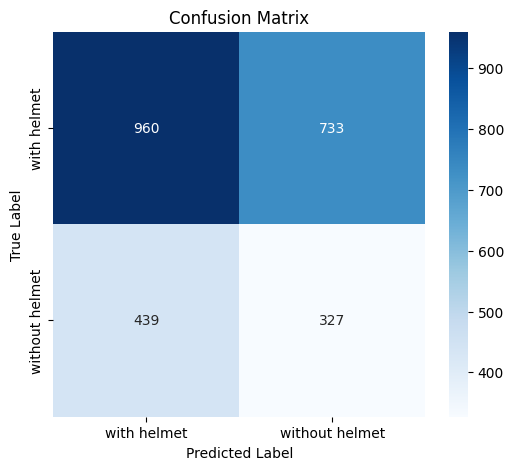

In [ ]:

cm = confusion_matrix (true_classes, pred_classes)

# Plot it using seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_labels,
            yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
print("Classification Report:")
print(classification_report(true_classes, pred_classes, target_names=class_labels))

Classification Report:
                precision    recall  f1-score   support

   with helmet       0.69      0.57      0.62      1693
without helmet       0.31      0.43      0.36       766

      accuracy                           0.52      2459
     macro avg       0.50      0.50      0.49      2459
  weighted avg       0.57      0.52      0.54      2459



In [ ]:
!pip install -q scikit-image opencv-python-headless


ERROR: Operation cancelled by user


In [ ]:
import os
import cv2
import numpy as np
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix


In [ ]:
def extract_hog_features(img_path, size=(128, 128)):
    img = cv2.imread(img_path)
    if img is None:
        raise ValueError(f"Could not read image {img_path}")
    img = cv2.resize(img, size)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    features = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                   cells_per_block=(2, 2), block_norm='L2-Hys')
    return features


In [ ]:
data_dir = "/content/drive/MyDrive/helmet detection/train"



In [ ]:
features = []
labels = []

for category in ['with helmet', 'without helmet']:
    folder = os.path.join(data_dir, category)
    label = 0 if category == 'with helmet' else 1

    for filename in os.listdir(folder):
        img_path = os.path.join(folder, filename)
        try:
            feat = extract_hog_features(img_path)
            features.append(feat)
            labels.append(label)
        except Exception as e:
            print(f"Skipped {img_path}: {e}")


In [ ]:
# Convert features and labels into NumPy arrays
X = np.array(features)
y = np.array(labels)

# Print shapes for verification
print("Feature shape:", X.shape)
print("Labels shape:", y.shape)


Feature shape: (3640, 8100)
Labels shape: (3640,)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create the Support Vector Machine (SVM) model
svm_model = SVC(kernel='linear', C=1.0, random_state=42)

# Train the model on HOG features
svm_model.fit(X_train, y_train)

print("✅ SVM model trained successfully!")


✅ SVM model trained successfully!


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Predict on test data
y_pred = svm_model.predict(X_test)

# Print confusion matrix
print("🔍 Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Print classification report
print("\n📊 Classification Report:")
print(classification_report(y_test, y_pred, target_names=['with_helmet', 'without_helmet']))

# Print overall accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"\n✅ Overall Accuracy: {accuracy:.2%}")



🔍 Confusion Matrix:
[[482  41]
 [ 35 170]]

📊 Classification Report:
                precision    recall  f1-score   support

   with_helmet       0.93      0.92      0.93       523
without_helmet       0.81      0.83      0.82       205

      accuracy                           0.90       728
     macro avg       0.87      0.88      0.87       728
  weighted avg       0.90      0.90      0.90       728


✅ Overall Accuracy: 89.56%


# Training the cnn model

In [ ]:
# Initializing the CNN model using Sequential
cnn = tf.keras.models.Sequential()

# Input layer for 128x128 RGB images
# increase the image size to increase more image data (give good reason)
cnn.add(tf.keras.Input(shape=(128, 128, 3)))

# First convolution block
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', padding='same'))
# Applies 32 filters of size 3x3 to detect basic patterns
cnn.add(tf.keras.layers.MaxPooling2D(pool_size=2))
# Reduces the feature map size by half (downsampling)

# Second convolution block
cnn.add(tf.keras.layers.Conv2D(filters=64, kernel_size=3, activation='relu', padding='same'))
# Uses 64 filters to capture more detailed features
cnn.add(tf.keras.layers.MaxPooling2D(pool_size=2))
# Again, reduces spatial dimensions by half

# Third convolution block
cnn.add(tf.keras.layers.Conv2D(filters=128, kernel_size=3, activation='relu', padding='same'))
# Learns even more complex visual patterns
cnn.add(tf.keras.layers.MaxPooling2D(pool_size=2))
# Further downsamples the feature map

# Fourth convolution block
cnn.add(tf.keras.layers.Conv2D(filters=128, kernel_size=3, activation='relu', padding='same'))
# Adds more depth to help extract high-level image features
cnn.add(tf.keras.layers.MaxPooling2D(pool_size=2))
# Final spatial reduction before flattening

# Flattening layer to convert 3D feature maps into 1D vector
cnn.add(tf.keras.layers.Flatten())

# Dropout layer to reduce overfitting by randomly disabling neurons
cnn.add(tf.keras.layers.Dropout(0.5))

# Dense layer with 256 neurons to learn patterns from features
cnn.add(tf.keras.layers.Dense(units=256, activation='relu'))

# Output layer with 1 neuron for binary classification
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

In [ ]:
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,338,497 (8.92 MB)

 Trainable params: 2,338,497 (8.92 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the model and store the history object
history = cnn.fit(train_ds, validation_data=val_ds, callbacks=[early_stop], epochs=20)

NameError: name 'early_stop' is not defined

In [ ]:
#adding early stoping
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
# Train the model and store the history object
history = cnn.fit(train_ds, validation_data=val_ds, callbacks=[early_stop], epochs=20)

ValueError: You must call `compile()` before using the model.

In [ ]:
cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])